# 06-任务控制块、任务栈与调度器原理


## 1. 本篇内容与学习目标

本篇是《FreeRTOS 从入门到实战》十七篇笔记中的第06篇，对应 `11freeRTOS任务结构体和调度.pptx`，原课标题为**任务结构体和调度**。

第05篇从优先级和状态解释“哪个任务可以运行”。本篇继续看内核如何保存任务信息、如何让暂停执行的任务从原位置继续，以及调度启动后谁负责系统节拍和空闲期间的工作。

| 课件主线 | 本篇学习内容 |
|---|---|
| 任务的核心本质 | TCB、任务句柄、状态链表节点与优先级 |
| 任务内存布局 | 任务栈与控制块，栈增长方向 |
| 关键栈指针 | `pxStack`、`pxTopOfStack` 与上下文保存和恢复 |
| 调度器启动 | `vTaskStartScheduler()` 的五个主要步骤 |
| Idle Task | 内存清理、空闲钩子和无应用任务就绪时的执行 |
| SysTick配置规范 | 由当前移植端口统一管理系统节拍 |

以下按PPT顺序整理。图是原课教学图，代码用于阅读与对照；必要的实现边界通过官方FreeRTOS-Kernel V10.5.1核对，未将这一参考版本视为已确认的课程源码版本。


## 2. 任务控制块：内核如何管理一个任务

任务入口函数只描述任务要执行的代码。要参与调度，一个任务还需要记录自己的优先级、状态关联和运行现场。FreeRTOS用**任务控制块TCB（Task Control Block）**保存这些管理信息。

原课将TCB比作“任务身份证”：调度器通过它辨认和管理任务。

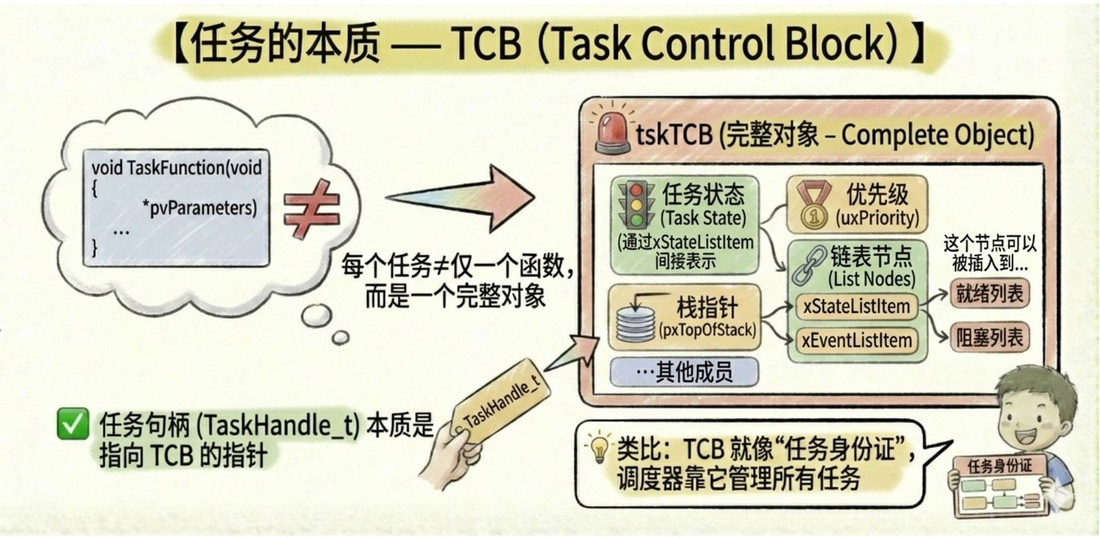

课件重点列出以下成员：

| 成员 | 作用 |
|---|---|
| `uxPriority` | 记录任务当前优先级，供调度器选择任务 |
| `xStateListItem` | 将任务关联到状态链表，例如就绪、延时阻塞或挂起链表 |
| `xEventListItem` | 将任务关联到事件等待链表 |
| `pxTopOfStack` | 保存任务上下文所对应的栈顶位置 |
| `pxStack` | 记录任务栈内存的起始地址 |

这里的链表节点是TCB中的成员。任务可以通过不同节点同时关联状态与事件等待，不能把两个节点理解为“一个任务只有一个状态字段，改数字就完成切换”。状态变化还需要内核调整相应链表。

### 任务句柄指向TCB

课件说明 `TaskHandle_t` 本质上是指向TCB的指针。参考版本在 `task.h` 中的声明为：

```c
struct tskTaskControlBlock;
typedef struct tskTaskControlBlock * TaskHandle_t;
```

在参考版本的 `tasks.c` 中，控制块结构先使用兼容旧调试器的类型名 `tskTCB`，再定义为 `TCB_t`。与本课有关的部分成员如下，省略了配置相关成员：

```c
// 参考内核TCB结构中的成员摘录，不是完整结构体定义
volatile StackType_t * pxTopOfStack;
ListItem_t xStateListItem;
ListItem_t xEventListItem;
UBaseType_t uxPriority;
StackType_t * pxStack;
char pcTaskName[configMAX_TASK_NAME_LEN];
```

创建任务后保存句柄，后续挂起、恢复或删除接口就能根据这个指针找到任务。应用应使用公开任务API管理任务，不能直接改内部TCB成员代替内核操作。

> 与第05篇衔接：删除任务后，这个句柄不再代表有效任务，即使变量还保存着旧地址也不能继续使用。任务句柄不是任务入口函数的地址。


## 3. 任务内存：任务栈与TCB

课件用“栈＋TCB”解释创建任务需要准备的两类内存。

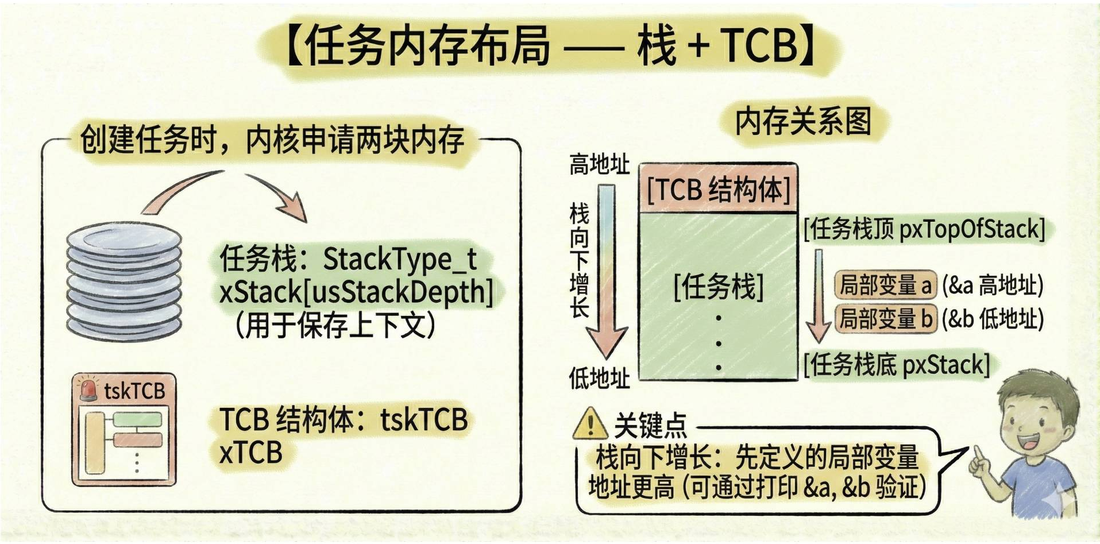

| 内存 | 保存什么 | 与任务创建的关系 |
|---|---|---|
| 任务栈 | 函数调用所需的数据、局部数据以及保存的寄存器上下文等 | 创建时确定栈容量，执行和切换时使用 |
| TCB | 优先级、链表节点、栈地址和其他任务管理信息 | 内核通过它管理任务 |

图中用以下形式表示任务栈：

```c
// 课件中的任务栈表示方式，用于说明元素类型和容量
StackType_t xStack[usStackDepth];
```

`usStackDepth` 表示栈元素数量，栈所占字节数为：

```text
栈容量（字节）= 栈深度 × sizeof(StackType_t)
```

这个容量只计算任务栈，TCB还需要另外的空间。变量名中的 `Stack` 指的是为任务使用的内存区域，不能据此把它随意声明成一个很快结束生命周期的自动局部数组。

课件写“创建任务时，内核申请两块内存”，对应动态创建的核心过程：内核为栈和控制块申请空间。第04篇的静态创建同样需要这两类内存，但由应用提供长期有效的栈缓冲区和 `StaticTask_t` 控制块缓冲区。

> 图示边界：图将TCB画在任务栈的高地址上方，是帮助理解两类内存的示意。它们的实际分配地址由内存管理实现和当前分配情况决定，不能保证相邻，也不能保证TCB总在任务栈的高地址一侧。


## 4. 栈向下增长与局部变量地址观察

课程所用Cortex-M4F端口的任务栈向下增长：使用更多栈空间时，栈指针向更低的地址移动。参考端口的 `portmacro.h` 用以下宏表示这一方向：

```c
#define portSTACK_GROWTH (-1)
```

任务栈缓冲区本身仍是一段从低地址到高地址的连续内存。向下增长描述的是使用栈空间时指针移动的方向，并不是数组元素地址倒着排列。

课件建议打印局部变量 `a`、`b` 的地址，观察示例中的分布。若在既有任务里做这个观察，可使用以下补充片段；它只帮助理解课件观察方法，不是原课给出的完整任务源码。

```c
#include <stdio.h>

// 放在实际任务函数内部，沿用工程已有的串口打印支持
int a = 0;
int b = 0;
printf("&a=%p, &b=%p\r\n", (void *)&a, (void *)&b);
```

使用 `%p` 输出地址，并把对应参数转换为 `void *`。实际串口打印还要求工程已经完成相应初始化和重定向。本篇没有生成或填写实际地址输出。

> 课件边界：图中写“先定义的局部变量地址更高”，这是示例布局，**C语言不保证局部变量按声明顺序分配地址**。编译器、优化与对齐可能改变布局，某些局部数据也可能保存在寄存器中。观察 `&a`、`&b` 可以了解这次编译的结果，不能把它当作判定栈增长方向的通用规则。

本课栈向下增长的依据是所选端口与处理器的栈机制，不能直接推广到FreeRTOS支持的所有处理器。


## 5. pxStack与pxTopOfStack的区别

课件第6页专门比较两个栈指针。区分它们，才能理解任务切换时内核保存了什么。

| 指针 | 本课向下增长栈中的含义 | 用途 |
|---|---|---|
| `pxStack` | 栈缓冲区起始地址，对应低地址边界 | 记录内存位置，参与栈边界检查，并供动态任务删除时释放栈内存 |
| `pxTopOfStack` | TCB中记录的上下文栈顶位置 | 为保存和恢复任务运行现场提供位置 |

`pxStack` 在同一个任务实例的正常生命周期内保持为这块栈内存的起始地址。`pxTopOfStack` 则随任务初始化和上下文保存而确定或更新。

### 创建时先准备初始上下文

参考版本对向下增长的栈，先从最后一个栈元素取得高地址侧的位置，再进行对齐：

```c
// 官方V10.5.1 tasks.c中的初始位置计算
pxTopOfStack = &(pxNewTCB->pxStack[ulStackDepth - (uint32_t)1]);
```

随后，端口的 `pxPortInitialiseStack()` 为新任务构造初始上下文，包含任务入口、任务参数和恢复执行所需的状态。函数返回准备好的栈顶位置，内核将它保存在TCB中。

这样首次启动任务也可以通过恢复上下文进入任务入口，无需先像普通C函数那样调用一遍任务。

> 指针纠正：课件将 `pxTopOfStack` 写成“最高有效地址”，容易把它与栈缓冲区的固定高地址边界混淆。构造初始上下文和保存运行现场都会占用栈空间，因此**保存的栈顶不等于固定的最高地址**。任务正在运行时，处理器的实际栈指针还会随调用变化，TCB中的值也不是每条指令同步更新的实时读数。

> 检查条件：记录 `pxStack` 并不等于自动启用了栈溢出检测。内核检测还取决于 `configCHECK_FOR_STACK_OVERFLOW` 等配置及对应钩子，检测也不能保证捕获每一种越界。本篇只解释该指针与栈边界的关系。


## 6. 上下文切换：保存后从原位置继续

上下文是任务恢复执行所需的运行现场，包括寄存器值、执行位置及相关状态。任务各自有栈，才能在交替执行时保留各自的现场。

课件将这一过程概括为“切换时压入寄存器，恢复时弹出寄存器”。在本课Cortex-M4F端口上，可按以下顺序理解：

1. 任务A执行到某个位置，发生需要切换任务的调度条件。
2. 处理器异常机制与端口切换代码共同将需要保留的现场保存到任务A的栈。
3. 保存后的栈顶位置写回任务A的TCB，即更新 `pxTopOfStack`。
4. 调度器选择接下来运行的任务B。
5. 端口从任务B的TCB取得它保存的栈顶，恢复现场，使任务B继续执行。

若B此前没有运行过，恢复的是创建时准备的初始上下文，于是进入B的任务入口；若B已经运行过，恢复后从其暂停的位置继续。

> 实现补充：当前Cortex-M4F端口由PendSV承担常规任务切换，部分寄存器由硬件自动保存，其他现场由端口代码处理。TCB中的 `pxTopOfStack` 放在首成员位置，便于切换代码定位。课件的“压入/弹出”是整体过程的简化描述，不是要求应用自己编写保存寄存器代码。

这也解释了第05篇恢复任务后为什么不会从入口重新开始：任务的控制块和栈仍然存在，恢复后的执行使用原来的上下文。


## 7. vTaskStartScheduler的启动流程

应用完成必要硬件初始化、创建任务并检查创建结果后，调用调度器启动接口：

```c
void vTaskStartScheduler(void);
```

从这个调用开始，内核负责决定各个任务何时执行。课件用五个步骤说明启动过程。

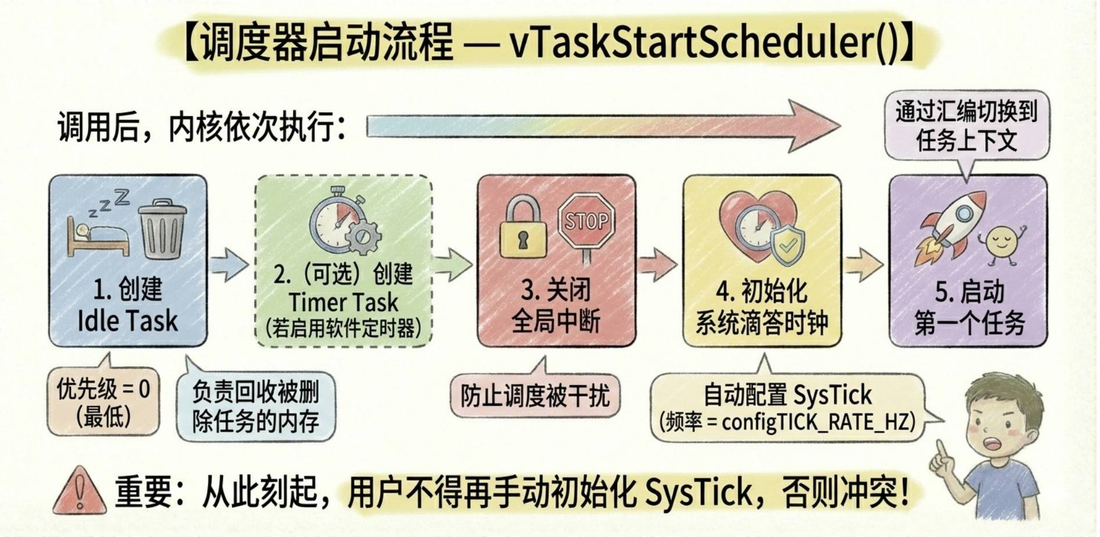

| 顺序 | 课件步骤 | 作用和条件 |
|---|---|---|
| 1 | 创建Idle Task | 以优先级0创建空闲任务，准备空闲执行与清理工作 |
| 2 | 可选创建Timer Task | 当 `configUSE_TIMERS == 1` 时创建软件定时器服务任务 |
| 3 | 关闭中断以保护启动 | 防止节拍在启动准备过程中干扰内核 |
| 4 | 初始化系统滴答时钟 | 当前端口配置SysTick，使系统节拍频率符合 `configTICK_RATE_HZ` |
| 5 | 启动第一个任务 | 端口通过恢复上下文进入任务执行 |

这是核心流程图，实际内核还会初始化调度状态、tick计数等数据。创建Idle Task或已启用的Timer Task失败时，不能继续正常启动调度。

创建了Idle Task，不等于首先执行的一定是Idle Task。内核启动时执行准备好的就绪任务，具体选择与优先级及配置有关。

### 启动时使用哪类内存

若采用动态分配，工程除了已创建的应用任务，还要为内核任务保留足够内存。若参考版本启用了静态分配，Idle Task会通过 `vApplicationGetIdleTaskMemory()` 取得应用提供的缓冲区；Timer Task启用时也需要相应的内存准备。这些回调已在第04篇整理。

> 中断范围核对：图中写“关闭全局中断”，这里保留它保护启动过程的含义。官方V10.5.1 Cortex-M4F端口的 `portDISABLE_INTERRUPTS()` 使用BASEPRI屏蔽相应优先级范围的中断，不能理解为所有异常和所有高紧急程度中断都被关闭。

在当前Cortex-M4F正常运行情况下，启动调度后不会回到原来的主循环继续执行普通初始化。若调试发现 `vTaskStartScheduler()` 返回或启动过程断言，应检查内核任务创建所需内存、配置及移植连接。该函数返回类型为 `void`，不能把它的返回值当作创建任务时的状态码。


## 8. Idle Task的第一项工作：延后清理任务资源

Idle Task是调度器启动时自动创建的空闲任务，优先级为0。课件将其作用分为内存回收、钩子回调和系统兜底。

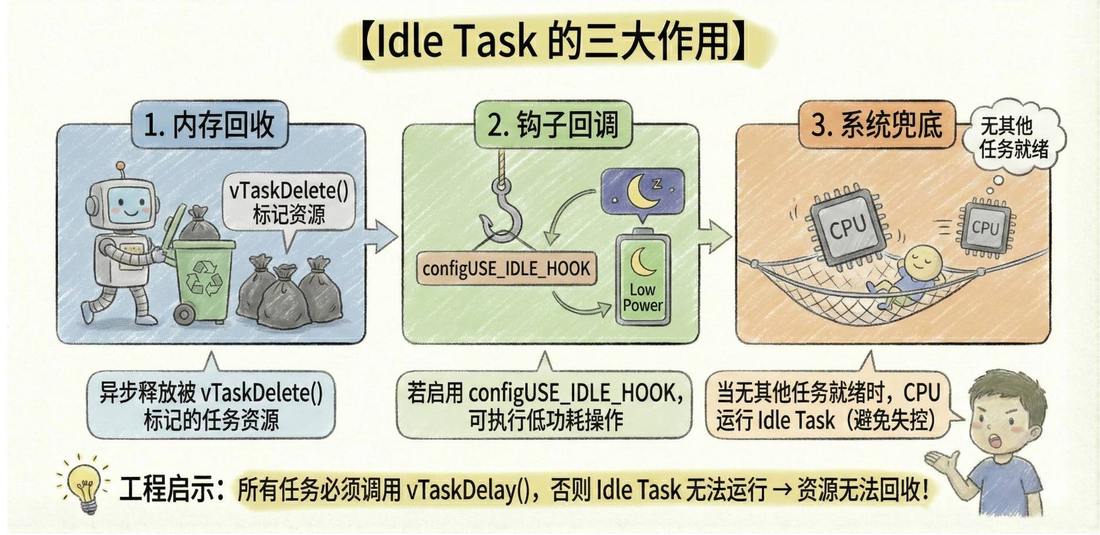

本篇先看内存回收。一个任务删除自身后，不能在继续使用自己栈的过程中把栈直接释放，因此内核将需要延后清理的任务放入待清理结构，再由Idle Task处理。

参考版本的Idle任务循环调用 `prvCheckTasksWaitingTermination()`，检查这些任务，再执行控制块和栈的相应清理。

> 回收边界：原图概括为“释放被 `vTaskDelete()` 标记的任务资源”。延续第05篇的核对，官方V10.5.1单核实现中，任务自删会延后交给Idle Task；一个任务删除另一个任务可在删除调用内直接清理。静态栈与控制块归应用所有，内核不会把它们作为动态内存释放。业务代码另外申请或持有的资源仍由应用负责。

若总有优先级高于0的任务保持就绪，Idle Task可能长期得不到CPU。任务自删积累的待清理资源就无法及时回收，后续动态创建任务可能因此缺少内存。

课件用 `vTaskDelay()` 提醒应用任务在等待期间释放CPU。更完整的条件是：调度安排要让Idle Task获得执行机会。多个任务各自调用了延时，也不保证某个时刻一定没有更高优先级任务就绪。

> 使用边界：队列、信号量等等待也能使应用任务阻塞，不要求每个任务必须采用 `vTaskDelay()`。不要挂起或删除Idle Task，也不要让它的处理路径长期忙运行或进入阻塞。


## 9. Idle钩子与没有应用任务就绪时的执行

### 钩子回调

课件说明启用 `configUSE_IDLE_HOOK` 后，可以在空闲执行路径中加入背景处理，也举了低功耗操作作为用途。

在工程的 `FreeRTOSConfig.h` 中，开关形式为：

```c
#define configUSE_IDLE_HOOK 1
```

启用后，应用还要提供以下接口的实际定义，供内核调用：

```c
void vApplicationIdleHook(void);
```

钩子在Idle Task上下文中执行。它应保持简短，不能调用可能阻塞的API，例如带正延时的 `vTaskDelay()` 或带等待时间的队列接收。它也没有固定调用周期，不能把它当作周期任务使用。

若不需要该回调，配置 `configUSE_IDLE_HOOK` 为0即可；**关闭空闲钩子不会取消Idle Task**，内核的空闲任务与资源清理仍然存在。

> 低功耗边界：开启钩子只让内核调用应用函数，并不会自动进入某种低功耗模式。具体休眠、唤醒和时间维护需要与当前平台及端口配合，课件没有给出这部分实现，本篇不添加独立低功耗方案。

### 没有应用任务就绪时

当其他任务都在等待、挂起或已经删除，CPU仍有一个有效的执行入口，即Idle Task。它检查待清理资源，执行已启用的空闲钩子，并保留最低优先级的执行路径。

因此“没有应用任务可运行”不会让CPU进入一个没有任务上下文的状态。更高优先级任务重新就绪后，内核再按当前调度配置安排它执行。

课件称这个作用为“系统兜底”，指始终有空闲任务可执行，不能据此推导为Idle Task能自动修复任意任务错误。


## 10. SysTick由当前端口统一配置

课件在启动流程与总结中重复强调：调度器启动时已经初始化SysTick，用户不能再按裸机方式手动配置它，否则会冲突。

在本课工程中，SysTick提供系统tick。移植端口根据时钟和 `configTICK_RATE_HZ` 配置节拍，tick再支持延时计时、时间片及相关内核调度。

| 位置 | 本课应如何处理 |
|---|---|
| `FreeRTOSConfig.h` | 让CPU时钟配置与实际芯片一致，核对 `configTICK_RATE_HZ` |
| 当前端口的 `port.c` | 由端口完成节拍定时器初始化和中断处理 |
| 原裸机初始化或延时模块 | OS模式下排除原来的 `SysTick_Config()` 等重复配置 |
| 原中断文件与启动向量 | 延续第03篇的SysTick、SVC和PendSV映射，避免重复或错误的处理函数 |

在参考Cortex-M4F端口中，`xPortStartScheduler()` 调用 `vPortSetupTimerInterrupt()` 配置节拍。当前正常周期tick的重装值计算依据为：

```text
SysTick重装值 = configSYSTICK_CLOCK_HZ / configTICK_RATE_HZ - 1
```

参考端口在没有单独指定SysTick时钟时使用 `configCPU_CLOCK_HZ`。例如工程节拍为1000 Hz，tick间隔为1 ms；时钟配置不匹配或被其他模块重写后，任务延时也会受到影响。

> 规范范围：课程要求的是当前SysTick方案由内核端口统一管理，避免应用和端口各配一套。FreeRTOS支持其他端口及受控的节拍实现，这不是所有平台都必须用SysTick的规则。本课继续使用已移植的方案。

初始化顺序也要对应：若SysTick只在调度启动期间开始计数，此前不能把依赖SysTick计数的延时当作已经可用。第03篇的非中断式轮询延时也需要满足这个前提。调度运行后，也不应为调用原裸机延时而重新初始化SysTick。


## 11. 原课要点与工程对照

PPT最后把任务、栈、调度启动和Idle工作连起来。按本篇已经说明的边界，可对照以下要点：

| 原课要点 | 工程中应理解或核对的内容 |
|---|---|
| 任务由TCB和栈组成 | 入口描述代码，TCB保存管理信息，栈支持独立运行现场 |
| 栈向下增长，栈顶指针用于恢复 | 当前Cortex-M4F端口向低地址使用栈空间，TCB保存的栈顶不是固定高地址边界 |
| 启动时自动创建Idle Task | 优先级0，动态或静态内存准备必须正确 |
| Idle Task需要有机会运行 | 避免持续由高于0优先级的任务占满CPU，保障延后清理等工作 |
| SysTick由端口初始化 | 系统时钟、节拍配置和异常入口一致，排除裸机重复初始化 |
| 应用任务等待期间释放CPU | 按业务使用延时或其他阻塞等待，并观察整体是否给Idle留下时间 |

课件提出的局部变量地址观察，需要在实际任务和当前编译配置下进行。除此之外，本课没有新增完整应用案例，工程检查继续沿用前几篇的任务，而不是另造一份课程项目。

如在开发板和调试器上对照本课，可核对以下位置。这里列的是验证方法，**未进行开发板编译、下载或运行**。

1. 核对工程所选端口的 `portSTACK_GROWTH`，确认任务栈方向。
2. 在实际任务中观察 `&a`、`&b`，记录本次编译布局，避免把地址关系当作声明顺序保证。
3. 在启动流程中观察Idle Task创建及可选Timer Task创建，确认配置和内存条件。
4. 在初始化、切出和切入的相关位置观察栈信息，区分 `pxStack` 的缓冲区起点、TCB保存的 `pxTopOfStack` 和处理器正在使用的栈指针。
5. 检查SysTick配置入口是否唯一，并对照既有任务延时，确认tick能正常推进。
6. 确认应用等待安排能给Idle执行机会，钩子路径没有阻塞调用。

资料说明：课程PPT共10页均已读取，按原课顺序覆盖教学内容，省略品牌结束页。必要的成员和端口边界参考 [FreeRTOS-Kernel V10.5.1](https://github.com/FreeRTOS/FreeRTOS-Kernel/tree/V10.5.1)，包括 `tasks.c`、`task.h` 及Cortex-M4F端口；未下载完整课程工程，未伪造地址或运行输出。
